<a href="https://colab.research.google.com/github/mrniktarasov/12-medical-image-analysis/blob/feature%2Feda-data/notebooks/vitaly_eda_data.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [5]:
# Часть 1. Работа Виталия: данные и разбиение

In [7]:
from google.colab import userdata
token = userdata.get('GH_TOKEN_SV')
!git clone -q https://{token}@github.com/mrniktarasov/12-medical-image-analysis.git /content/repo
%cd /content/repo
!git checkout feature/eda-data
!git pull
!git config user.name "Vitaly Sanin"
!git config user.email "sanin2005@yandex.ru"
!ls -a . src data

/content/repo
branch 'feature/eda-data' set up to track 'origin/feature/eda-data'.
Switched to a new branch 'feature/eda-data'
Already up to date.
.:
.   data  .gitignore  notebooks  requirements.txt
..  .git  LICENSE     README.md  src

data:
.  ..  metadata.csv

src:
.  ..  config.py  download_data.py


In [8]:
!sed -i '/^kaggle==/d' requirements.txt
!cat requirements.txt
!pip install -q -r requirements.txt

# Python 3.13.18 (Google Colab)
numpy==2.4.6
pandas==2.2.3
matplotlib==3.10.0
seaborn==0.13.2
pillow==11.3.0
scikit-learn==1.6.1
imagehash==4.3.2
tqdm==4.67.3


In [9]:
%%writefile src/config.py
from pathlib import Path

ROOT = Path(__file__).resolve().parents[1]
DATA_RAW = ROOT / "data" / "raw"
DATA_OCT = DATA_RAW / "OCT"
META = ROOT / "data" / "metadata.csv"
SPLITS = ROOT / "data" / "splits.csv"
FIGURES = ROOT / "reports" / "figures"

SEED = 42
CLASSES = ["CNV", "DME", "DRUSEN", "NORMAL"]

Overwriting src/config.py


In [10]:
import sys
sys.path.insert(0, "/content/repo")
from src import config
print(config.DATA_OCT)

!git add requirements.txt src/config.py
!git commit -m "chore: переход на Mendeley — путь DATA_OCT, убран kaggle"
!git push

/content/repo/data/raw/OCT
[feature/eda-data daaf6fd] chore: переход на Mendeley — путь DATA_OCT, убран kaggle
 2 files changed, 1 insertion(+), 1 deletion(-)
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (5/5), 532 bytes | 532.00 KiB/s, done.
Total 5 (delta 3), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (3/3), completed with 3 local objects.
To https://github.com/mrniktarasov/12-medical-image-analysis.git
   13a82b2..daaf6fd  feature/eda-data -> feature/eda-data


In [11]:
!df -h /content

Filesystem      Size  Used Avail Use% Mounted on
overlay         108G   92M  108G   1% /


In [12]:
%%writefile src/download_data.py
"""Скачивание Retinal OCT (Kermany, Mendeley Data v3) в data/raw/OCT."""
import hashlib
import shutil
import sys
import urllib.request
import zipfile
from pathlib import Path

from tqdm import tqdm

sys.path.insert(0, str(Path(__file__).resolve().parents[1]))
from src import config

URL = ("https://data.mendeley.com/public-files/datasets/rscbjbr9sj/files/"
       "810b2ce2-11c3-4424-996e-3bef36600907/file_downloaded")
SHA256 = "acbc42869440eec719361942d0ba560f132742230262f22e78bfb93eb5ea4563"
ZIP = config.DATA_RAW / "ZhangLabData.zip"
PREFIX = "CellData/OCT/"
EXPECTED = {"train": 108309, "test": 1000}


def download():
    part = ZIP.with_suffix(".part")
    req = urllib.request.Request(URL, headers={"User-Agent": "Mozilla/5.0"})
    with urllib.request.urlopen(req) as r, open(part, "wb") as f:
        total = int(r.headers.get("Content-Length", 0))
        with tqdm(total=total, unit="B", unit_scale=True, desc="download") as bar:
            while chunk := r.read(1 << 20):
                f.write(chunk)
                bar.update(len(chunk))
    part.rename(ZIP)


def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        while chunk := f.read(1 << 20):
            h.update(chunk)
    return h.hexdigest()


def extract():
    with zipfile.ZipFile(ZIP) as z:
        members = [m for m in z.namelist() if m.startswith(PREFIX)]
        for m in tqdm(members, desc="unzip"):
            z.extract(m, config.DATA_RAW)
    (config.DATA_RAW / "CellData" / "OCT").rename(config.DATA_OCT)
    shutil.rmtree(config.DATA_RAW / "CellData")


def check():
    ok = True
    for split, n in EXPECTED.items():
        got = sum(1 for _ in (config.DATA_OCT / split).glob("*/*.jpeg"))
        print(f"{split}: {got} (ожидалось {n})", "OK" if got == n else "MISMATCH")
        ok &= got == n
    return ok


def main():
    if config.DATA_OCT.exists():
        print("Данные уже есть:", config.DATA_OCT)
    else:
        config.DATA_RAW.mkdir(parents=True, exist_ok=True)
        if not ZIP.exists():
            download()
        print("Проверка SHA-256...")
        if sha256(ZIP) != SHA256:
            sys.exit(f"Хеш не совпал. Удалите {ZIP} и запустите снова.")
        extract()
        ZIP.unlink()
    sys.exit(0 if check() else 1)


if __name__ == "__main__":
    main()

Overwriting src/download_data.py


In [13]:
!python src/download_data.py
!ls data/raw/OCT data/raw/OCT/train

download: 100% 8.44G/8.44G [04:48<00:00, 29.3MB/s]
Проверка SHA-256...
unzip: 100% 109320/109320 [01:36<00:00, 1134.95it/s]
train: 108309 (ожидалось 108309) OK
test: 1000 (ожидалось 1000) OK
data/raw/OCT:
test  train

data/raw/OCT/train:
CNV  DME  DRUSEN  NORMAL


In [14]:
!git add src/download_data.py
!git commit -m "feat: download_data.py для Mendeley v3 (проверка SHA-256, только OCT)"
!git push

[feature/eda-data afec15a] feat: download_data.py для Mendeley v3 (проверка SHA-256, только OCT)
 1 file changed, 60 insertions(+), 30 deletions(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (4/4), done.
Writing objects: 100% (4/4), 1.63 KiB | 1.63 MiB/s, done.
Total 4 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/mrniktarasov/12-medical-image-analysis.git
   daaf6fd..afec15a  feature/eda-data -> feature/eda-data


In [15]:
import re
import pandas as pd
from PIL import Image
from tqdm.auto import tqdm
from src import config

PATTERN = re.compile(r"^(CNV|DME|DRUSEN|NORMAL)-(\d+)-(\d+)\.jpeg$")
root = config.DATA_OCT

rows, bad = [], []
for p in tqdm(sorted(root.glob("*/*/*.jpeg"))):
    split, folder = p.parts[-3], p.parts[-2]
    m = PATTERN.match(p.name)
    if not m or m.group(1) != folder:
        bad.append(p)
        continue
    with Image.open(p) as im:
        w, h, mode = im.width, im.height, im.mode
    rows.append({
        "path": p.relative_to(root).as_posix(),
        "split": split,
        "label": folder,
        "patient_id": m.group(2),
        "img_num": int(m.group(3)),
        "width": w, "height": h, "mode": mode,
        "file_size": p.stat().st_size,
    })

df = pd.DataFrame(rows)
df.to_csv(config.META, index=False)
print(df.shape, "| не подошли под шаблон:", len(bad))
df.head()

  0%|          | 0/109309 [00:00<?, ?it/s]

(109309, 9) | не подошли под шаблон: 0


,path,split,label,patient_id,img_num,width,height,mode,file_size
0,test/CNV/CNV-1032178-1.jpeg,test,CNV,1032178,1,1024,496,L,69392
1,test/CNV/CNV-1034361-1.jpeg,test,CNV,1034361,1,1024,496,L,73847
2,test/CNV/CNV-1034361-2.jpeg,test,CNV,1034361,2,1024,496,L,87609
3,test/CNV/CNV-1052341-1.jpeg,test,CNV,1052341,1,1024,496,L,76332
4,test/CNV/CNV-1106195-1.jpeg,test,CNV,1106195,1,1024,496,L,75900


In [16]:
print(pd.crosstab(df["label"], df["split"], margins=True))
print(df.groupby(["width", "height"]).size().sort_values(ascending=False).head())
print(df["mode"].value_counts())

split   test   train     All
label                       
CNV      250   37205   37455
DME      250   11348   11598
DRUSEN   250    8616    8866
NORMAL   250   51140   51390
All     1000  108309  109309
width  height
512    496       58037
768    496       29749
1536   496       11512
512    512        8659
1024   496        1329
dtype: int64
mode
L      109307
RGB         2
Name: count, dtype: int64


In [17]:
!git add data/metadata.csv
!git commit -m "data: metadata.csv для Mendeley v3 (109 309 снимков)"
!git push

[feature/eda-data 85784ed] data: metadata.csv для Mendeley v3 (109 309 снимков)
 1 file changed, 50161 insertions(+), 25336 deletions(-)
Enumerating objects: 7, done.
Counting objects: 100% (7/7), done.
Delta compression using up to 2 threads
Compressing objects: 100% (3/3), done.
Writing objects: 100% (4/4), 668.94 KiB | 2.06 MiB/s, done.
Total 4 (delta 2), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (2/2), completed with 2 local objects.
To https://github.com/mrniktarasov/12-medical-image-analysis.git
   afec15a..85784ed  feature/eda-data -> feature/eda-data


In [18]:
print("Разных размеров:", df.groupby(["width", "height"]).ngroups)
print(df[df["mode"] == "RGB"][["path", "width", "height"]], "\n")

img = pd.crosstab(df["label"], df["split"])
pat = df.groupby(["label", "split"])["patient_id"].nunique().unstack()
summary = pd.DataFrame({
    "снимков train": img["train"],
    "доля train, %": (img["train"] / img["train"].sum() * 100).round(1),
    "снимков test": img["test"],
    "пациентов train": pat["train"],
    "пациентов test": pat["test"],
})
print(summary, "\n")
print("Дисбаланс train (max/min):", round(img["train"].max() / img["train"].min(), 1))

per = df.groupby(["split", "patient_id"]).size()
print("\nСнимков на пациента:\n", per.groupby("split").describe().round(1))

multi = (df.groupby("patient_id")["label"].nunique() > 1).sum()
total = df["patient_id"].nunique()
by_split = df.groupby("split")["patient_id"].nunique().sum()
print(f"\nПациентов всего: {total}; сумма по выборкам: {by_split}; "
      f"есть и в train, и в test: {by_split - total}")
print("Пациентов с несколькими диагнозами:", multi)

Разных размеров: 8
                                  path  width  height
603    test/DRUSEN/DRUSEN-52917-1.jpeg    642     277
716  test/DRUSEN/DRUSEN-9012418-1.jpeg    900     455 

        снимков train  доля train, %  снимков test  пациентов train  \
label                                                                 
CNV             37205           34.4           250              791   
DME             11348           10.5           250              709   
DRUSEN           8616            8.0           250              713   
NORMAL          51140           47.2           250             3434   

        пациентов test  
label                   
CNV                178  
DME                167  
DRUSEN             169  
NORMAL             171   

Дисбаланс train (max/min): 5.9

Снимков на пациента:
         count  mean   std  min  25%   50%   75%    max
split                                                 
test    635.0   1.6   1.4  1.0  1.0   1.0   2.0   18.0
train  4785.0  22.6

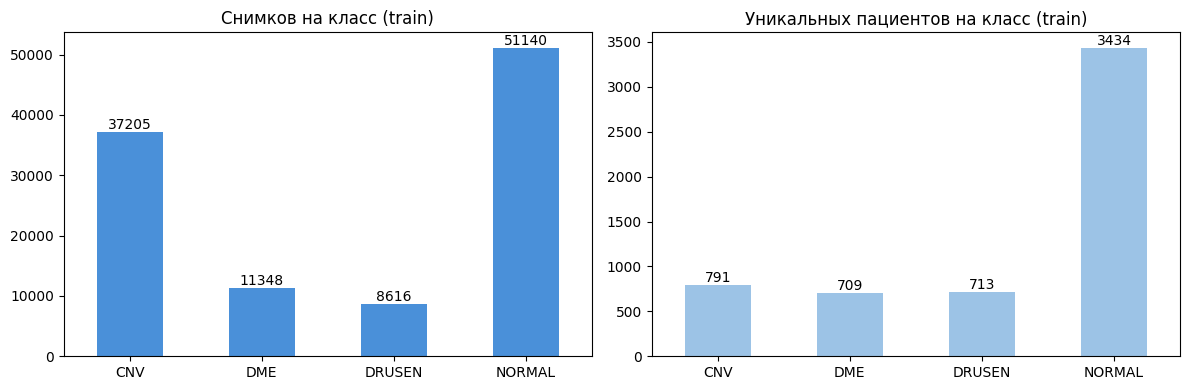

In [19]:
import matplotlib.pyplot as plt

config.FIGURES.mkdir(parents=True, exist_ok=True)
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
img["train"].plot.bar(ax=ax[0], color="#4A90D9")
ax[0].set_title("Снимков на класс (train)")
pat["train"].plot.bar(ax=ax[1], color="#9CC3E6")
ax[1].set_title("Уникальных пациентов на класс (train)")
for a in ax:
    a.set_xlabel("")
    a.tick_params(axis="x", rotation=0)
    for c in a.containers:
        a.bar_label(c)
plt.tight_layout()
plt.savefig(config.FIGURES / "class_balance.png", dpi=150)
plt.show()

In [20]:
import io, os, hashlib
import imagehash
from concurrent.futures import ProcessPoolExecutor

def scan(rel):
    try:
        data = (root / rel).read_bytes()
        md5 = hashlib.md5(data).hexdigest()
        with Image.open(io.BytesIO(data)) as im:
            im.load()
            ph = str(imagehash.phash(im.convert("L")))
        return rel, md5, ph, ""
    except Exception as e:
        return rel, None, None, repr(e)

with ProcessPoolExecutor(os.cpu_count()) as ex:
    res = list(tqdm(ex.map(scan, df["path"], chunksize=256), total=len(df)))

h = pd.DataFrame(res, columns=["path", "md5", "phash", "error"])
df = df.drop(columns=["md5", "phash", "error"], errors="ignore").merge(h, on="path")
h.to_csv(config.ROOT / "data" / "hashes.csv", index=False)
print("Проверено:", len(h), "| ошибок чтения:", (h["error"] != "").sum())

  0%|          | 0/109309 [00:00<?, ?it/s]

Проверено: 109309 | ошибок чтения: 0


In [21]:
def dup_report(key):
    d = df[df.duplicated(key, keep=False)]
    s = d.groupby(key).agg(n=("path", "size"),
                           labels=("label", "nunique"),
                           patients=("patient_id", "nunique"),
                           splits=("split", "nunique"))
    print(f"[{key}] групп: {len(s)}, файлов: {s['n'].sum()}, лишних копий: {s['n'].sum() - len(s)}")
    print(f"   разные метки: {(s['labels'] > 1).sum()} | разные пациенты: {(s['patients'] > 1).sum()} "
          f"| train и test: {(s['splits'] > 1).sum()}")
    return d.sort_values(key)

print(df.loc[df["error"] != "", ["path", "error"]], "\n")
dup_md5 = dup_report("md5")
dup_ph = dup_report("phash")
dup_ph[["path", "label", "patient_id", "split", "phash"]].head(10)

Empty DataFrame
Columns: [path, error]
Index: [] 

[md5] групп: 7092, файлов: 14958, лишних копий: 7866
   разные метки: 269 | разные пациенты: 19 | train и test: 0
[phash] групп: 7823, файлов: 16737, лишних копий: 8914
   разные метки: 338 | разные пациенты: 72 | train и test: 0


,path,label,patient_id,split,phash
30474,train/CNV/CNV-8184974-150.jpeg,CNV,8184974,train,800c2f57f5278f5c
30475,train/CNV/CNV-8184974-151.jpeg,CNV,8184974,train,800c2f57f5278f5c
32103,train/CNV/CNV-8796318-32.jpeg,CNV,8796318,train,802679d9b6a3c95e
32102,train/CNV/CNV-8796318-31.jpeg,CNV,8796318,train,802679d9b6a3c95e
5316,train/CNV/CNV-1699976-203.jpeg,CNV,1699976,train,802a55d52f4ad5af
5318,train/CNV/CNV-1699976-205.jpeg,CNV,1699976,train,802a55d52f4ad5af
5321,train/CNV/CNV-1699976-208.jpeg,CNV,1699976,train,802a55d52f4ad5af
5320,train/CNV/CNV-1699976-207.jpeg,CNV,1699976,train,802a55d52f4ad5af
5319,train/CNV/CNV-1699976-206.jpeg,CNV,1699976,train,802a55d52f4ad5af
5317,train/CNV/CNV-1699976-204.jpeg,CNV,1699976,train,802a55d52f4ad5af


md5-групп с разными метками: 269 | phash-групп с разными md5: 935
label
CNV + DRUSEN       187
DRUSEN + NORMAL     53
CNV + DME           21
DME + NORMAL         8
Name: count, dtype: int64


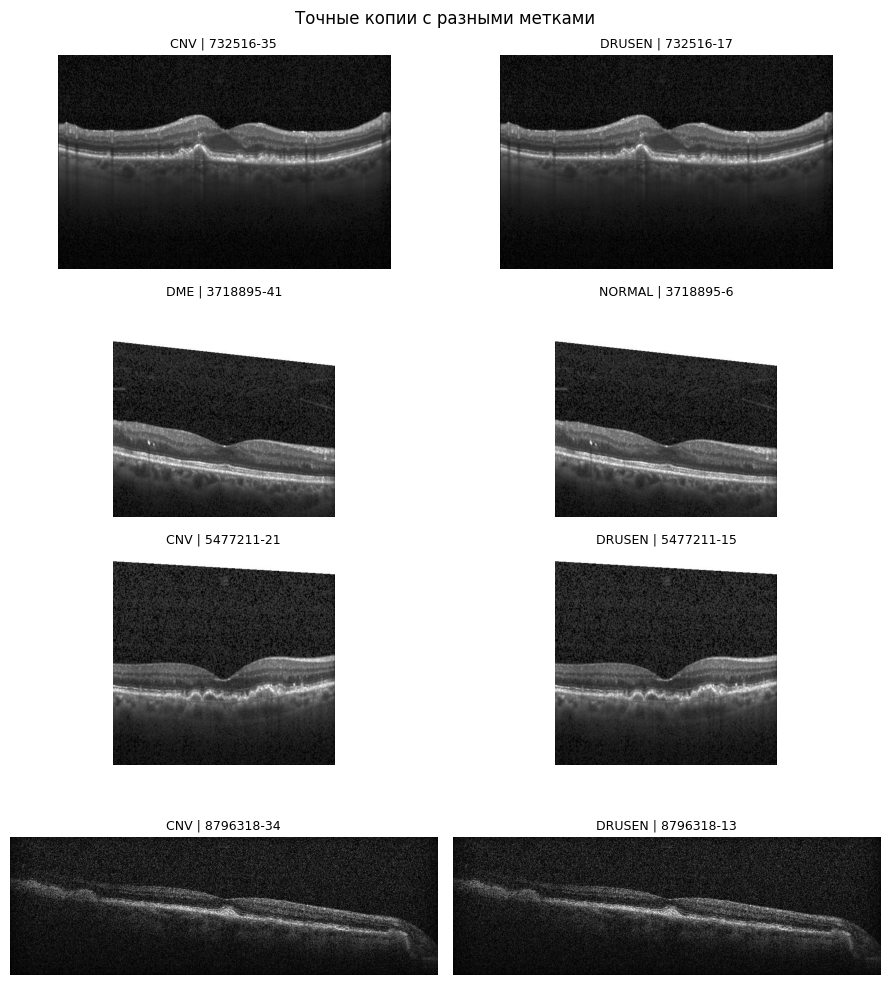

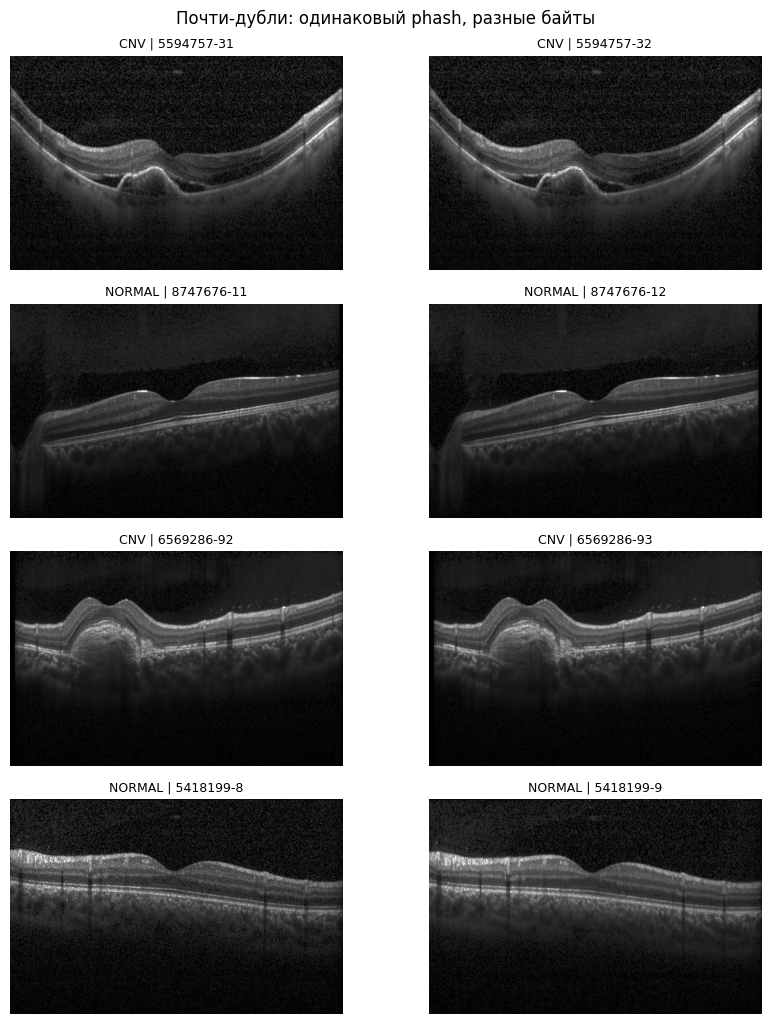

In [22]:
import random

dup = df[df.duplicated("md5", keep=False)]
conf = [k for k, x in dup.groupby("md5") if x["label"].nunique() > 1]
near = [k for k, x in df[df.duplicated("phash", keep=False)].groupby("phash")
        if x["md5"].nunique() > 1]
print("md5-групп с разными метками:", len(conf), "| phash-групп с разными md5:", len(near))
print(df[df["md5"].isin(conf)].groupby("md5")["label"]
      .agg(lambda s: " + ".join(sorted(s.unique()))).value_counts())

def show(groups, key, title, n=4):
    pick = random.Random(config.SEED).sample(groups, min(n, len(groups)))
    fig, ax = plt.subplots(len(pick), 2, figsize=(9, 2.6 * len(pick)))
    for i, k in enumerate(pick):
        for j, (_, r) in enumerate(df[df[key] == k].head(2).iterrows()):
            ax[i, j].imshow(Image.open(root / r["path"]), cmap="gray")
            ax[i, j].set_title(f"{r['label']} | {r['patient_id']}-{r['img_num']}", fontsize=9)
    for a in ax.ravel():
        a.axis("off")
    fig.suptitle(title)
    plt.tight_layout()
    plt.show()

show(conf, "md5", "Точные копии с разными метками")
show(near, "phash", "Почти-дубли: одинаковый phash, разные байты")

In [23]:
df = df.sort_values(["phash", "patient_id", "img_num"]).reset_index(drop=True)
tr = df["split"] == "train"
n_lab = df.groupby("phash")["label"].transform("nunique")
first = ~df.duplicated("phash")

df["reason"] = ""
df.loc[tr & (n_lab > 1), "reason"] = "conflict_label"
df.loc[tr & (n_lab == 1) & ~first, "reason"] = "duplicate"

print(df.loc[tr, "reason"].replace("", "keep").value_counts())
print("Дублей внутри test (не трогаем):", df[~tr].duplicated("phash", keep=False).sum())
clean = df[tr & (df["reason"] == "")]
print(pd.DataFrame({"было": df[tr]["label"].value_counts(),
                    "стало": clean["label"].value_counts()}))

reason
keep              99082
duplicate          8525
conflict_label      702
Name: count, dtype: int64
Дублей внутри test (не трогаем): 50
         было  стало
label               
NORMAL  51140  49649
CNV     37205  31033
DME     11348  10671
DRUSEN   8616   7729


In [25]:
from sklearn.model_selection import StratifiedGroupKFold


target = clean["label"].value_counts(normalize=True)
best = None
for seed in range(5):
    sg = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=seed)
    for k, (_, vi) in enumerate(sg.split(clean, clean["label"], clean["patient_id"])):
        if not 0.08 < len(vi) / len(clean) < 0.12:
            continue
        dev = (clean.iloc[vi]["label"].value_counts(normalize=True) - target).abs().max()
        if best is None or dev < best[0]:
            best = (dev, seed, k, vi)

dev, seed, k, val_idx = best
print(f"Выбран seed={seed}, fold={k}: макс. отклонение {dev * 100:.1f} п.п., "
      f"val = {len(val_idx)} ({len(val_idx) / len(clean):.1%})")
val_ids = set(clean.iloc[val_idx]["patient_id"])


keep = tr & (df["reason"] == "")
df["new_split"] = "excluded"
df.loc[~tr, "new_split"] = "test"
df.loc[keep, "new_split"] = "train"
df.loc[keep & df["patient_id"].isin(val_ids), "new_split"] = "val"


S = ["train", "val", "test"]
pid = {s: set(df.loc[df["new_split"] == s, "patient_id"]) for s in S}
ph = {s: set(df.loc[df["new_split"] == s, "phash"]) for s in S}
for a, b in [("train", "val"), ("train", "test"), ("val", "test")]:
    print(f"{a}∩{b}: пациентов {len(pid[a] & pid[b])}, phash {len(ph[a] & ph[b])}")


print(pd.crosstab(df["label"], df["new_split"], margins=True))
print((pd.crosstab(df["label"], df["new_split"], normalize="columns") * 100).round(1))


out = (df[["path", "new_split", "label", "patient_id", "reason"]]
       .rename(columns={"new_split": "split"}).sort_values("path"))
out.to_csv(config.SPLITS, index=False)
print("Сохранено:", config.SPLITS, out.shape)

Выбран seed=3, fold=2: макс. отклонение 0.5 п.п., val = 10534 (10.6%)
train∩val: пациентов 0, phash 0
train∩test: пациентов 0, phash 0
val∩test: пациентов 0, phash 0
new_split  excluded  test  train    val     All
label                                          
CNV            6172   250  27789   3244   37455
DME             677   250   9495   1176   11598
DRUSEN          887   250   6897    832    8866
NORMAL         1491   250  44367   5282   51390
All            9227  1000  88548  10534  109309
new_split  excluded  test  train   val
label                                 
CNV            66.9  25.0   31.4  30.8
DME             7.3  25.0   10.7  11.2
DRUSEN          9.6  25.0    7.8   7.9
NORMAL         16.2  25.0   50.1  50.1
Сохранено: /content/repo/data/splits.csv (109309, 5)


In [26]:
!git add data/splits.csv reports/figures/class_balance.png
!git status --short
!git commit -m "data: splits.csv — очистка дублей, val по пациентам (seed=3, fold=2)"
!git push

A  data/splits.csv
A  reports/figures/class_balance.png
[feature/eda-data 0dbb080] data: splits.csv — очистка дублей, val по пациентам (seed=3, fold=2)
 2 files changed, 109310 insertions(+)
 create mode 100644 data/splits.csv
 create mode 100644 reports/figures/class_balance.png
Enumerating objects: 9, done.
Counting objects: 100% (9/9), done.
Delta compression using up to 2 threads
Compressing objects: 100% (5/5), done.
Writing objects: 100% (7/7), 412.02 KiB | 3.05 MiB/s, done.
Total 7 (delta 1), reused 0 (delta 0), pack-reused 0
remote: Resolving deltas: 100% (1/1), completed with 1 local object.
To https://github.com/mrniktarasov/12-medical-image-analysis.git
   85784ed..0dbb080  feature/eda-data -> feature/eda-data


## Выводы по данным (Виталий)

**Источник.** Kermany et al., Mendeley Data v3.

**Объём.** 109 309 снимков: train 108 309, test 1 000 (по 250 на класс). Битых файлов нет (полная декодировка всех снимков).

**Баланс.** В train NORMAL 47,2%, CNV 34,4%, DME 10,5%, DRUSEN 8,0%; дисбаланс 5,9 раза (после очистки — 6,4). По числу пациентов три класса болезней почти равны (709–791), дисбаланс снимков создают в основном пациенты с CNV (≈47 снимков на пациента против 12–16 в других классах).

**Пациенты.** 5 420 уникальных ID; пересечений train/test по ID нет. Снимков на пациента: медиана 10, максимум 813. У 787 пациентов несколько диагнозов.

**Дубли.** MD5: 7 866 точных копий; phash: 8 914 визуально одинаковых снимков (соседние B-сканы одного пациента). 269 групп точных копий имеют разные метки (чаще CNV + DRUSEN). Между train и test дублей нет.

**Очистка train.** Исключено 9 227 снимков (8,5%): 8 525 дублей (оставлен один снимок из группы) и 702 снимка с противоречивыми метками.

**Разбиение (`data/splits.csv`).** train 88 548 / val 10 534 / test 1 000. Val выделен из train по пациентам (StratifiedGroupKFold, выбран вариант seed=3, fold=2 с отклонением долей классов ≤ 0,5 п.п.). Общих пациентов и phash между выборками нет.

**Ограничения.** Число ID (5 420) больше, чем 4 686 пациентов в публикации: возможно, ID обозначает глаз или визит. В test 50 файлов входят в группы дублей. Два снимка test/DRUSEN цветные (RGB) и нестандартного размера.

**Рекомендации команде.** Использовать только `splits.csv`;